# RutaPro · Notebook 01: Preparación y análisis exploratorio (EDA)

**Fase 3 del trabajo.** Se revisa la calidad de las tres tablas y se caracterizan las interacciones, los usuarios y los cursos. Al final se fijan dos decisiones que usarán todos los modelos:

1. qué cuenta como **interacción positiva** (relevancia), y
2. cómo se **parten los datos en el tiempo** (entrenamiento, validación y prueba) sin fuga de información.

> Recordatorio: usuarios e interacciones son **simulados** (ver notebook 00). Los patrones que aparecen aquí reflejan las reglas de simulación; el EDA sirve para verificar que esos patrones son plausibles y para tomar decisiones de modelamiento.

**Contenido**
1. Carga de datos
2. Calidad de datos: duplicados, faltantes, claves y consistencia temporal
3. Embudo de eventos
4. Evolución temporal
5. Actividad por usuario
6. Popularidad de cursos y cola larga
7. Categorías e idioma
8. Nivel del estudiante frente a dificultad del curso
9. Calificaciones
10. Dispersión de la matriz usuario-curso
11. Definición de interacción positiva
12. Partición temporal para la evaluación
13. Conclusiones del EDA

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

BASE = Path.cwd().parent if Path.cwd().name == "02_Notebooks" else Path.cwd()
DATA = BASE / "01_Datos"
FIG = BASE / "04_Informe" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Estilo de gráficos: superficie clara, ejes discretos, un color por serie en orden fijo
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9890"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", dpi=160, bbox_inches="tight")

cursos = pd.read_csv(DATA / "cursos.csv")
usuarios = pd.read_csv(DATA / "usuarios.csv", parse_dates=["fecha_registro"])
inter = pd.read_csv(DATA / "interacciones.csv", parse_dates=["timestamp"])
print(f"cursos {cursos.shape} | usuarios {usuarios.shape} | interacciones {inter.shape}")

cursos (107, 19) | usuarios (150, 9) | interacciones (3680, 7)


## 2. Calidad de datos

In [2]:
calidad = pd.DataFrame({
    "filas": [len(cursos), len(usuarios), len(inter)],
    "filas duplicadas exactas": [cursos.duplicated().sum(), usuarios.duplicated().sum(),
                                 inter.drop(columns="interaction_id").duplicated().sum()],
    "llave duplicada": [cursos["course_id"].duplicated().sum(), usuarios["user_id"].duplicated().sum(),
                        inter["interaction_id"].duplicated().sum()],
}, index=["cursos", "usuarios", "interacciones"])
calidad["eventos repetidos (usuario, curso, evento)"] = [np.nan, np.nan,
    inter.duplicated(["user_id", "course_id", "evento"]).sum()]
calidad

,filas,filas duplicadas exactas,llave duplicada,"eventos repetidos (usuario, curso, evento)"
cursos,107,0,0,NaN
usuarios,150,0,0,NaN
interacciones,3680,0,0,0.0


In [3]:
faltantes = pd.concat({
    "cursos": cursos.isna().sum(), "usuarios": usuarios.isna().sum(), "interacciones": inter.isna().sum()
}).rename("faltantes").to_frame()
faltantes = faltantes[faltantes["faltantes"] > 0]
faltantes["% de la tabla"] = [round(100 * v / {"cursos": len(cursos), "usuarios": len(usuarios),
                               "interacciones": len(inter)}[t], 1) for (t, _), v in faltantes["faltantes"].items()]
display(faltantes)
print("Calificación faltante fuera de 'finalizacion':",
      inter.loc[inter["evento"] != "finalizacion", "calificacion"].isna().all())
print("Finalizaciones sin calificación:", inter.loc[inter["evento"] == "finalizacion", "calificacion"].isna().sum())
print("\nValores imputados en el catálogo (marcados en el notebook 00):")
print(cursos.filter(like="_imputad").sum().to_string())

,,faltantes,% de la tabla
interacciones,calificacion,3204,87.1


Calificación faltante fuera de 'finalizacion': True
Finalizaciones sin calificación: 0

Valores imputados en el catálogo (marcados en el notebook 00):
dificultad_imputada     8
duracion_imputada       8
rating_imputado        17
n_resenas_imputado      8


In [4]:
# Integridad referencial y consistencia temporal
reg = inter.merge(usuarios[["user_id", "fecha_registro"]], on="user_id")
orden = {"vista": 0, "favorito": 1, "inscripcion": 2, "finalizacion": 3}
seq = inter.assign(o=inter["evento"].map(orden)).sort_values("timestamp")
primer = seq.groupby(["user_id", "course_id"]).first()
ins = inter[inter.evento == "inscripcion"].set_index(["user_id", "course_id"])["timestamp"]
fin = inter[inter.evento == "finalizacion"].set_index(["user_id", "course_id"])["timestamp"]
checks = pd.Series({
    "user_id de interacciones existe en usuarios": inter["user_id"].isin(usuarios["user_id"]).all(),
    "course_id de interacciones existe en cursos": inter["course_id"].isin(cursos["course_id"]).all(),
    "usuarios sin ninguna interacción": int((~usuarios["user_id"].isin(inter["user_id"])).sum()),
    "cursos sin ninguna interacción": int((~cursos["course_id"].isin(inter["course_id"])).sum()),
    "eventos antes de la fecha de registro": int((reg["timestamp"] < reg["fecha_registro"]).sum()),
    "pares cuyo primer evento no es 'vista'": int((primer["evento"] != "vista").sum()),
    "finalizaciones sin inscripción previa": int((~fin.index.isin(ins.index)).sum()),
    "finalizaciones anteriores a su inscripción": int((fin - ins.reindex(fin.index) < pd.Timedelta(0)).sum()),
    "rango de fechas": f"{inter.timestamp.min():%d/%m/%Y} – {inter.timestamp.max():%d/%m/%Y}",
})
checks.to_frame("resultado")

,resultado
user_id de interacciones existe en usuarios,True
course_id de interacciones existe en cursos,True
usuarios sin ninguna interacción,0
cursos sin ninguna interacción,0
eventos antes de la fecha de registro,0
pares cuyo primer evento no es 'vista',0
finalizaciones sin inscripción previa,0
finalizaciones anteriores a su inscripción,0
rango de fechas,07/01/2026 – 14/10/2026


**Interpretación.** Las tres tablas están limpias: no hay filas duplicadas, las llaves son únicas y todas las interacciones apuntan a usuarios y cursos que existen. El único campo con faltantes es `calificacion` (87 % vacío), pero es un faltante **estructural**: solo se califica al finalizar un curso, y ninguna finalización quedó sin nota. La secuencia de cada par es coherente (siempre empieza con una vista, ninguna finalización ocurre sin inscripción ni antes de ella) y no hay eventos anteriores al registro del estudiante. En el catálogo, los valores imputados ya están marcados desde el notebook 00, así que no se requiere más limpieza.

## 3. Embudo de eventos

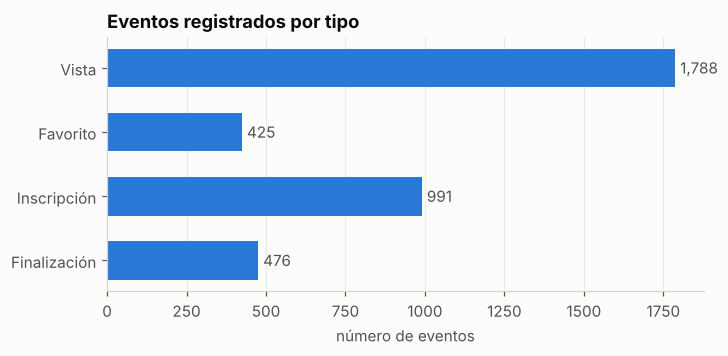

,% de pares usuario-curso
vista → favorito,23.8
vista → inscripción,55.4
inscripción → finalización,48.0


In [5]:
embudo = inter["evento"].value_counts().reindex(["vista", "favorito", "inscripcion", "finalizacion"])
pares = inter.groupby(["user_id", "course_id"])["evento"].agg(set)
conv = pd.Series({
    "vista → favorito": pares.map(lambda s: "favorito" in s).mean(),
    "vista → inscripción": pares.map(lambda s: "inscripcion" in s).mean(),
    "inscripción → finalización": (pares.map(lambda s: "finalizacion" in s).sum()
                                   / pares.map(lambda s: "inscripcion" in s).sum()),
})
fig, ax = plt.subplots(figsize=(7, 3))
y = np.arange(len(embudo))[::-1]
ax.barh(y, embudo.values, color=AZUL, height=0.6)
ax.set_yticks(y, ["Vista", "Favorito", "Inscripción", "Finalización"])
for yi, v in zip(y, embudo.values):
    ax.text(v + 15, yi, f"{v:,}", va="center", color=TXT2)
ax.set_title("Eventos registrados por tipo"); ax.set_xlabel("número de eventos"); ax.grid(axis="y", visible=False)
guardar(fig, "01_embudo"); plt.show()
(conv * 100).round(1).rename("% de pares usuario-curso").to_frame()

**Interpretación.** De cada 100 cursos que un estudiante abre, unos 55 terminan en inscripción y la mitad de esas inscripciones llega a finalizarse (48 %). El favorito es poco usado (24 % de los pares), así que es una señal débil y escasa. Para el negocio esto significa que la vista por sí sola no indica interés: casi la mitad de los cursos vistos se descartan. Por eso la relevancia se define a partir de la inscripción (sección 11) y no de la vista.

## 4. Evolución temporal

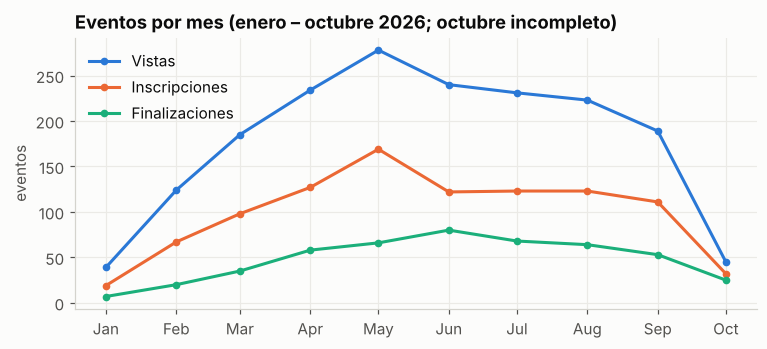

Registros de usuarios por mes:
fecha_registro
2026-01    22
2026-02    17
2026-03    20
2026-04    26
2026-05    13
2026-06    18
2026-07    18
2026-08    16
Freq: M


In [6]:
mensual = (inter.assign(mes=inter.timestamp.dt.to_period("M").dt.to_timestamp())
           .pivot_table(index="mes", columns="evento", values="interaction_id", aggfunc="count")
           .reindex(columns=["vista", "inscripcion", "finalizacion"]))
fig, ax = plt.subplots(figsize=(8, 3.2))
for col, c, lab in zip(mensual.columns, [AZUL, NARANJA, AQUA], ["Vistas", "Inscripciones", "Finalizaciones"]):
    ax.plot(mensual.index, mensual[col], color=c, lw=2, marker="o", ms=4, label=lab)
ax.set_title("Eventos por mes (enero – octubre 2026; octubre incompleto)"); ax.set_ylabel("eventos")
ax.legend(loc="upper left", frameon=False)
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
guardar(fig, "02_eventos_mes"); plt.show()
nuevos = usuarios.fecha_registro.dt.to_period("M").value_counts().sort_index()
print("Registros de usuarios por mes:"); print(nuevos.to_string())

**Interpretación.** La actividad crece de enero a mayo, a medida que se registran más estudiantes, se mantiene estable entre junio y septiembre y cae en octubre solo porque el periodo observado termina el 14/10. Los registros llegan de forma continua (entre 13 y 26 estudiantes nuevos por mes hasta agosto). Esto tiene una consecuencia directa para la evaluación: si se usa una sola fecha de corte para todos, los estudiantes que se registraron tarde casi no tienen historial en entrenamiento. Este punto se retoma en la sección 12.

## 5. Actividad por usuario

,count,mean,std,min,25%,50%,75%,max
eventos,150.0,24.5,13.1,4.0,15.0,22.0,32.8,67.0
cursos_vistos,150.0,11.9,6.6,3.0,7.0,11.0,15.0,34.0
inscripciones,150.0,6.6,3.8,0.0,4.0,6.0,8.8,21.0


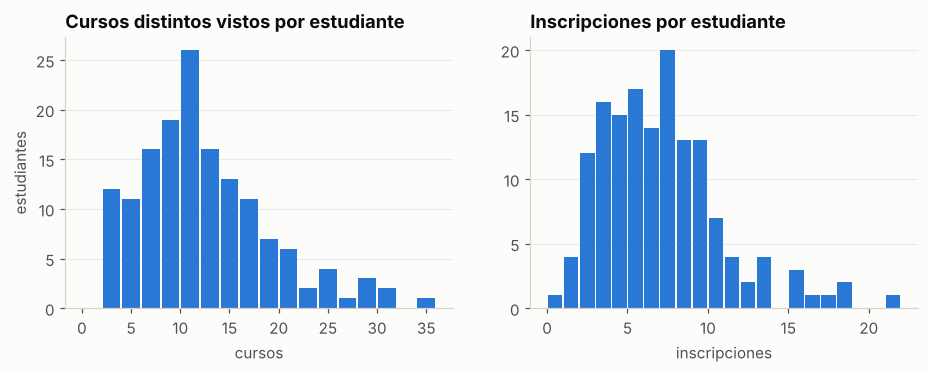

Estudiantes con menos de 3 inscripciones: 17


In [7]:
act_u = inter.groupby("user_id").agg(eventos=("interaction_id", "count"), cursos_vistos=("course_id", "nunique"))
act_u["inscripciones"] = inter[inter.evento == "inscripcion"].groupby("user_id").size().reindex(act_u.index, fill_value=0)
display(act_u.describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(act_u["cursos_vistos"], bins=range(0, act_u.cursos_vistos.max() + 3, 2), color=AZUL, rwidth=0.9)
axes[0].set_title("Cursos distintos vistos por estudiante"); axes[0].set_xlabel("cursos"); axes[0].set_ylabel("estudiantes")
axes[1].hist(act_u["inscripciones"], bins=range(0, act_u.inscripciones.max() + 2), color=AZUL, rwidth=0.9)
axes[1].set_title("Inscripciones por estudiante"); axes[1].set_xlabel("inscripciones")
for a in axes: a.grid(axis="x", visible=False)
guardar(fig, "03_actividad_usuario"); plt.show()
print("Estudiantes con menos de 3 inscripciones:", (act_u.inscripciones < 3).sum())

**Interpretación.** La actividad es asimétrica a la derecha, como en plataformas reales: el estudiante típico mira 11 cursos y se inscribe en 6, pero hay usuarios muy activos con más de 15 inscripciones. 17 estudiantes tienen menos de 3 inscripciones. Ese grupo es difícil para el filtrado colaborativo, porque hay poca información para encontrar vecinos parecidos, y será el que se use para mostrar el manejo de historial corto y *cold start*.

## 6. Popularidad de cursos y cola larga

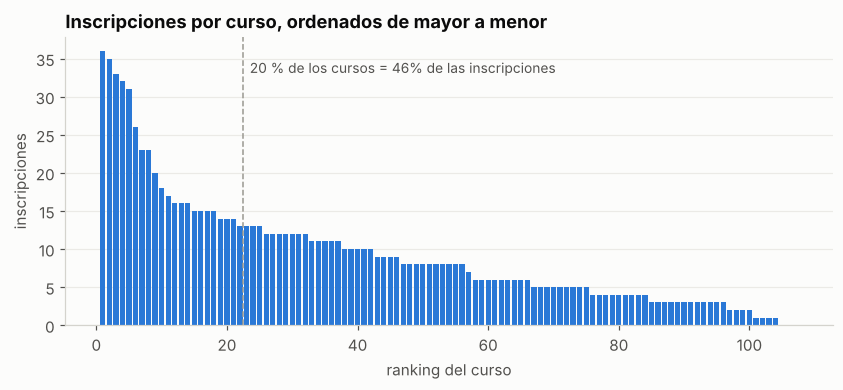

Cursos necesarios para cubrir el 50 % de inscripciones: 25 de 107
Coeficiente de Gini de la popularidad: 0.41
Cursos sin inscripciones: 3

Top 10 cursos por inscripciones:


,titulo,plataforma,idioma,categoria,dificultad,inscripciones
course_id,,,,,,
C024,Curso de Excel Intermedio,Platzi,es,Excel,Intermedio,36
C005,Curso de Business Intelligence: Utilidad y Áre...,Platzi,es,Análisis de Datos,Intermedio,35
C094,Introducción a SQL,DataCamp,es,SQL y Bases de Datos,Básico,33
C017,Excel avanzado: importación y análisis de datos,edX,es,Excel,Avanzado,32
C016,Curso de Excel Avanzado para Análisis de Datos,Platzi,es,Excel,Avanzado,31
C018,Curso de Excel Básico,Platzi,es,Excel,Básico,26
C025,Excel: gestión de datos,edX,es,Excel,Intermedio,23
C064,Introducción a Power BI,DataCamp,es,Power BI,Básico,23
C038,Curso de Comunicación Efectiva para Equipos de...,Platzi,es,Habilidades Blandas,Avanzado,20


In [8]:
pos_curso = (inter[inter.evento == "inscripcion"].groupby("course_id").size()
             .reindex(cursos.course_id, fill_value=0).sort_values(ascending=False))
acum = pos_curso.cumsum() / pos_curso.sum()
top20 = acum.iloc[int(np.ceil(0.2 * len(pos_curso))) - 1]
n_50 = int((acum < 0.5).sum() + 1)

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(1, len(pos_curso) + 1)
ax.bar(x, pos_curso.values, color=AZUL, width=0.8)
corte = int(np.ceil(0.2 * len(pos_curso)))
ax.axvline(corte + 0.5, color=GRIS, lw=1, ls="--")
ax.text(corte + 1.5, pos_curso.max() * 0.92, f"20 % de los cursos = {top20:.0%} de las inscripciones", color=TXT2, fontsize=9)
ax.set_title("Inscripciones por curso, ordenados de mayor a menor"); ax.set_xlabel("ranking del curso"); ax.set_ylabel("inscripciones")
ax.grid(axis="x", visible=False)
guardar(fig, "04_cola_larga"); plt.show()

gini = 1 - 2 * np.trapezoid(np.r_[0, pos_curso.sort_values().cumsum() / pos_curso.sum()], dx=1 / len(pos_curso))
print(f"Cursos necesarios para cubrir el 50 % de inscripciones: {n_50} de {len(pos_curso)}")
print(f"Coeficiente de Gini de la popularidad: {gini:.2f}")
print(f"Cursos sin inscripciones: {(pos_curso == 0).sum()}")
print("\nTop 10 cursos por inscripciones:")
display(cursos.set_index("course_id").loc[pos_curso.index[:10], ["titulo", "plataforma", "idioma", "categoria", "dificultad"]]
        .assign(inscripciones=pos_curso.iloc[:10].values))

**Interpretación.** La popularidad está concentrada, pero no de forma extrema: el 20 % de los cursos reúne el 46 % de las inscripciones, 25 de los 107 cursos cubren la mitad y el índice de Gini es 0.41. Solo 3 cursos no tienen ninguna inscripción. Los cursos más populares son cortos, en español y de las categorías transversales a casi todos los puestos (Excel, BI, SQL introductorio). Esto anticipa que el **baseline de popularidad será un rival difícil**. También anticipa que un buen modelo personalizado debe aportar algo más que repetir el top: llegar a la cola larga, que concentra la otra mitad de las inscripciones.

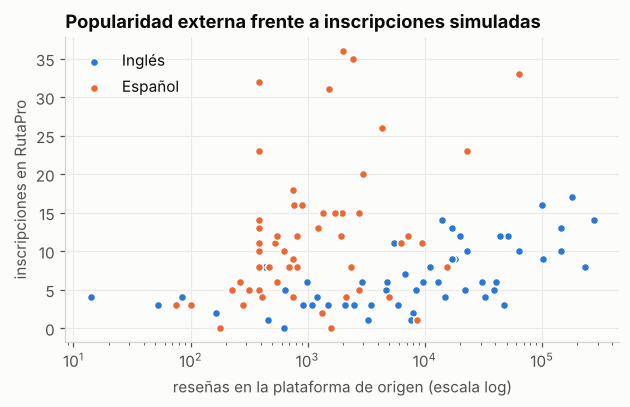

Correlación de Spearman: 0.21


In [9]:
# ¿La popularidad en RutaPro sigue a la popularidad real en la plataforma de origen?
df = cursos.set_index("course_id").assign(inscripciones=pos_curso)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for idi, c, lab in [("en", AZUL, "Inglés"), ("es", NARANJA, "Español")]:
    d = df[df.idioma == idi]
    ax.scatter(d["n_resenas"], d["inscripciones"], s=28, color=c, edgecolor="#fcfcfb", lw=1, label=lab)
ax.set_xscale("log"); ax.set_xlabel("reseñas en la plataforma de origen (escala log)"); ax.set_ylabel("inscripciones en RutaPro")
ax.set_title("Popularidad externa frente a inscripciones simuladas"); ax.legend(frameon=False)
guardar(fig, "05_popularidad_externa"); plt.show()
rho = df[["n_resenas", "inscripciones"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman: {rho:.2f}")

**Interpretación.** La relación entre las reseñas en la plataforma de origen y las inscripciones en RutaPro es positiva pero débil (Spearman = 0.21). La razón principal es el idioma: los cursos en español (naranja) tienen menos reseñas en su plataforma, pero los estudiantes peruanos los prefieren. Dentro de cada plataforma, los cursos más reseñados sí atraen más inscripciones (así se definió la regla de simulación, usando el percentil de reseñas por plataforma). Para el modelamiento, el número de reseñas sirve como variable del curso, pero no debe usarse como sustituto de la popularidad dentro de RutaPro.

## 7. Categorías e idioma

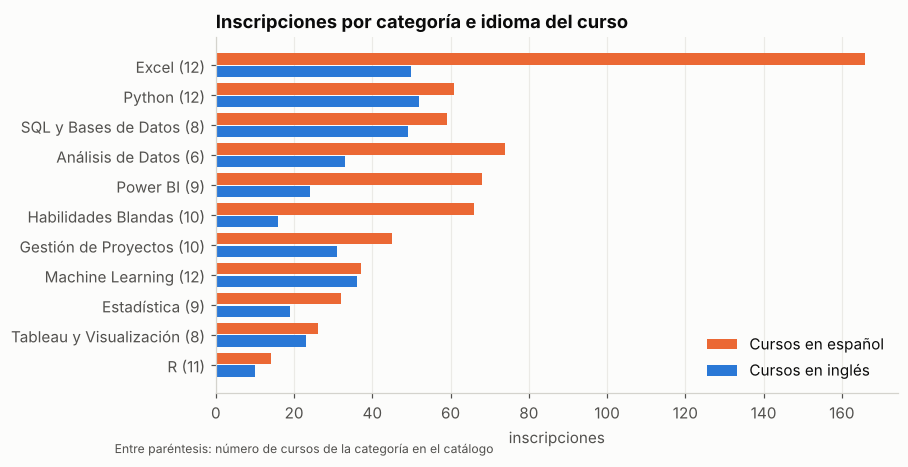

Proporción de inscripciones en cursos en español según idioma del estudiante:


idioma,en,es
idioma_preferido,,
es,0.13,0.87
es+en,0.46,0.54


In [10]:
ins_det = inter[inter.evento == "inscripcion"].merge(cursos, on="course_id").merge(usuarios, on="user_id")
tab = pd.crosstab(ins_det["categoria"], ins_det["idioma"]).reindex(columns=["es", "en"])
tab = tab.loc[tab.sum(axis=1).sort_values().index]
oferta = cursos.groupby("categoria").size()

fig, ax = plt.subplots(figsize=(8, 4.2))
yy = np.arange(len(tab)); h = 0.38
ax.barh(yy + h / 2 + 0.02, tab["es"], height=h, color=NARANJA, label="Cursos en español")
ax.barh(yy - h / 2 - 0.02, tab["en"], height=h, color=AZUL, label="Cursos en inglés")
ax.set_yticks(yy, [f"{c} ({oferta[c]})" for c in tab.index])
ax.set_title("Inscripciones por categoría e idioma del curso"); ax.set_xlabel("inscripciones")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, "Entre paréntesis: número de cursos de la categoría en el catálogo", color=TXT2, fontsize=8)
guardar(fig, "06_categoria_idioma"); plt.show()

print("Proporción de inscripciones en cursos en español según idioma del estudiante:")
pd.crosstab(ins_det["idioma_preferido"], ins_det["idioma"], normalize="index").round(2)

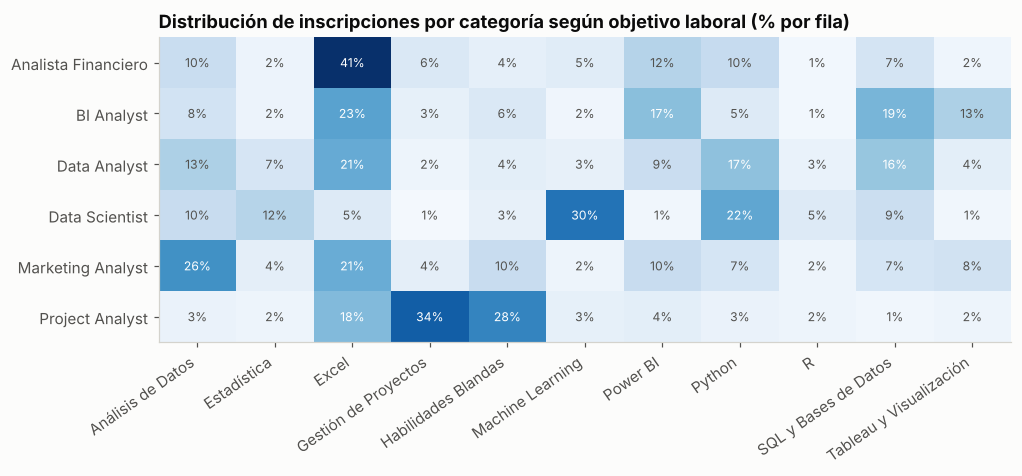

In [11]:
# Afinidad observada: ¿cada objetivo laboral se inscribe en las categorías esperadas?
obs = pd.crosstab(ins_det["objetivo_laboral"], ins_det["categoria"], normalize="index")
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(obs.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(obs.shape[1]), obs.columns, rotation=35, ha="right"); ax.set_yticks(range(obs.shape[0]), obs.index)
for i in range(obs.shape[0]):
    for j in range(obs.shape[1]):
        v = obs.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.16 else TXT2)
ax.grid(False); ax.set_title("Distribución de inscripciones por categoría según objetivo laboral (% por fila)")
guardar(fig, "07_objetivo_categoria"); plt.show()

**Interpretación.** El 65 % de las inscripciones son en cursos en español. Los estudiantes que solo leen español eligen cursos en español en el 87 % de los casos, y los bilingües se reparten casi a la mitad. Excel es la categoría más demandada con mucha diferencia, porque es útil para casi todos los objetivos laborales y tiene 7 cursos en español. R y Tableau son las menos demandadas.

El mapa de calor confirma que cada perfil se inscribe en lo que su puesto necesita:
- **Project Analyst:** Gestión de Proyectos (34 %) y Habilidades Blandas (28 %).
- **Data Scientist:** Machine Learning (30 %) y Python (22 %).
- **Analista Financiero:** Excel (41 %).
- **BI Analyst:** Excel, SQL, Power BI y Tableau.

Es decir, las características del usuario (objetivo laboral, intereses) y del curso (categoría, habilidades) tienen poder para explicar las elecciones. Eso favorece a los modelos de contenido y al híbrido LightFM, y es un sesgo que debe reconocerse porque proviene de las reglas de simulación.

## 8. Nivel del estudiante frente a dificultad del curso

dificultad,Básico,Intermedio,Avanzado
nivel,,,
Básico,66.3,26.0,7.7
Intermedio,50.6,36.8,12.6
Avanzado,53.6,30.6,15.7


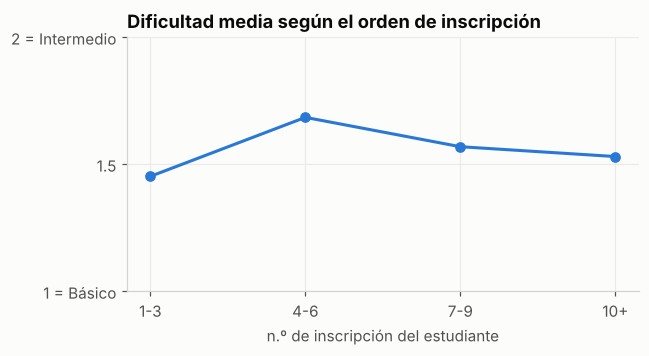

,mean,count
tramo,,
1-3,1.45,427
4-6,1.68,304
7-9,1.57,160
10+,1.53,100


In [12]:
niv = pd.crosstab(ins_det["nivel"], ins_det["dificultad"], normalize="index").reindex(
    index=["Básico", "Intermedio", "Avanzado"], columns=["Básico", "Intermedio", "Avanzado"])
display((niv * 100).round(1))
# Progresión: dificultad media de las inscripciones según su orden en la historia del estudiante
NUM = {"Básico": 1, "Intermedio": 2, "Avanzado": 3}
ins_det = ins_det.sort_values("timestamp")
ins_det["orden"] = ins_det.groupby("user_id").cumcount() + 1
ins_det["tramo"] = pd.cut(ins_det["orden"], [0, 3, 6, 9, 100], labels=["1-3", "4-6", "7-9", "10+"])
prog = ins_det.assign(d=ins_det.dificultad.map(NUM)).groupby("tramo", observed=True)["d"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(prog.index.astype(str), prog["mean"], color=AZUL, lw=2, marker="o", ms=6)
ax.set_ylim(1, 2); ax.set_yticks([1, 1.5, 2], ["1 = Básico", "1.5", "2 = Intermedio"])
ax.set_title("Dificultad media según el orden de inscripción"); ax.set_xlabel("n.º de inscripción del estudiante")
guardar(fig, "08_progresion_nivel"); plt.show()
prog.round(2)

**Interpretación.** Los estudiantes de nivel básico se concentran en cursos básicos (66 %), y la proporción de cursos intermedios y avanzados aumenta con el nivel declarado. Aun así, incluso los estudiantes avanzados toman sobre todo cursos básicos (54 %). Esto se explica por el catálogo: 69 de los 107 cursos son de nivel básico y solo 9 son avanzados, así que la oferta limita la progresión. La dificultad media sube entre las primeras inscripciones (1.45) y la 4.ª a 6.ª (1.68), y luego baja levemente, porque los estudiantes con historiales largos empiezan categorías nuevas desde el nivel básico. Para el sistema, la dificultad del curso y el nivel del estudiante son variables útiles para no recomendar cursos fuera del alcance del estudiante.

## 9. Calificaciones

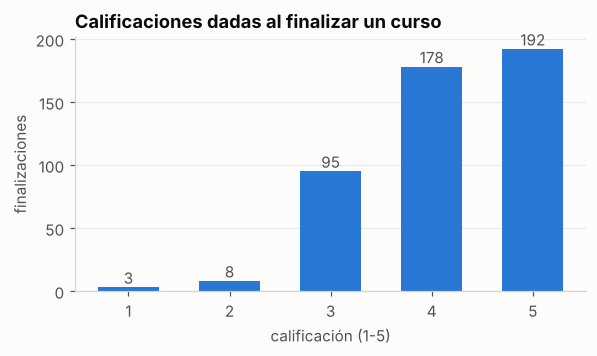

Calificación media: 4.15 | % con nota ≥ 4: 78%


,mean,count
encaja,,
no coincide,3.93,253
nivel declarado = dificultad,4.40,223


In [13]:
fin_det = inter[inter.evento == "finalizacion"].merge(cursos, on="course_id").merge(usuarios, on="user_id")
dist = fin_det["calificacion"].value_counts().sort_index().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(dist.index, dist.values, color=AZUL, width=0.6)
for x_, v in dist.items(): ax.text(x_, v + 3, str(v), ha="center", color=TXT2)
ax.set_title("Calificaciones dadas al finalizar un curso"); ax.set_xlabel("calificación (1-5)"); ax.set_ylabel("finalizaciones")
ax.grid(axis="x", visible=False)
guardar(fig, "09_calificaciones"); plt.show()
fin_det["encaja"] = fin_det["nivel"] == fin_det["dificultad"]
print(f"Calificación media: {fin_det.calificacion.mean():.2f} | % con nota ≥ 4: {(fin_det.calificacion >= 4).mean():.0%}")
fin_det.groupby("encaja")["calificacion"].agg(["mean", "count"]).rename(index={True: "nivel declarado = dificultad", False: "no coincide"}).round(2)

**Interpretación.** Las calificaciones son altas (media 4.15; el 78 % es 4 o 5), un patrón típico de las plataformas educativas, donde quien termina un curso suele estar satisfecho. La nota es claramente mayor cuando la dificultad del curso coincide con el nivel declarado del estudiante (4.40 frente a 3.93). Como solo existe calificación para el 13 % de los eventos, se usa como señal complementaria y no como la variable objetivo. El problema es de **feedback implícito**.

## 10. Dispersión de la matriz usuario-curso

,valor
celdas posibles (usuarios × cursos),16050
pares con algún evento,1788
densidad (cualquier evento),11.1%
pares positivos (inscripción),991
densidad (positivos),6.2%
dispersión (positivos),93.8%


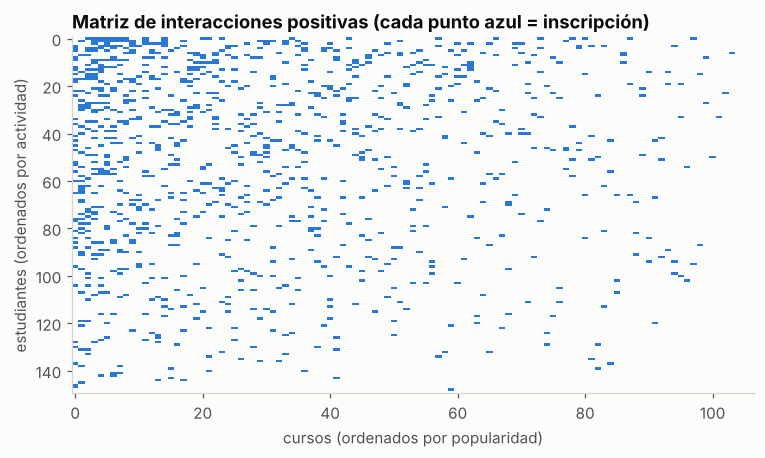

In [14]:
M = pd.crosstab(inter["user_id"], inter["course_id"]).clip(upper=1).reindex(columns=cursos.course_id, fill_value=0)
M_pos = (pd.crosstab(ins_det["user_id"], ins_det["course_id"]).clip(upper=1)
         .reindex(index=usuarios.user_id, columns=cursos.course_id, fill_value=0))
disp = pd.Series({
    "celdas posibles (usuarios × cursos)": M.size,
    "pares con algún evento": int(M.values.sum()),
    "densidad (cualquier evento)": f"{M.values.mean():.1%}",
    "pares positivos (inscripción)": int(M_pos.values.sum()),
    "densidad (positivos)": f"{M_pos.values.mean():.1%}",
    "dispersión (positivos)": f"{1 - M_pos.values.mean():.1%}",
})
display(disp.to_frame("valor"))
orden_u = M_pos.sum(axis=1).sort_values(ascending=False).index
orden_c = M_pos.sum(axis=0).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.imshow(M_pos.loc[orden_u, orden_c].values, cmap=mpl.colors.ListedColormap(["#fcfcfb", AZUL]),
          aspect="auto", interpolation="nearest")
ax.set_xlabel("cursos (ordenados por popularidad)"); ax.set_ylabel("estudiantes (ordenados por actividad)")
ax.set_title("Matriz de interacciones positivas (cada punto azul = inscripción)"); ax.grid(False)
guardar(fig, "10_matriz_dispersion"); plt.show()

**Interpretación.** De las 16 050 combinaciones posibles entre estudiantes y cursos, solo el 6.2 % tiene una inscripción: la matriz es **93.8 % dispersa**. En el gráfico se ve la estructura típica: unos pocos estudiantes muy activos (arriba) y unos pocos cursos muy populares (izquierda) concentran los puntos, mientras que la esquina inferior derecha está casi vacía. Con esta dispersión, el KNN colaborativo encontrará vecinos con pocas coincidencias, y el número de vecinos *k* será un hiperparámetro sensible. Los modelos que usan atributos (contenido y LightFM) pueden compensar parcialmente la falta de interacciones.

## 11. Definición de interacción positiva

Para evaluar Top-N se necesita decidir, para cada par usuario-curso, si el curso fue **relevante** para el estudiante.

| Señal | ¿Positiva? | Motivo |
|---|---|---|
| `vista` | No | Solo indica exposición; el estudiante puede haber descartado el curso. |
| `favorito` | No (señal débil) | Indica intención, pero sin compromiso. Se usa como peso en modelos que aceptan intensidad. |
| `inscripcion` | **Sí** | El estudiante decidió invertir tiempo en el curso: es la acción que RutaPro quiere provocar. |
| `finalizacion` | **Sí** | Siempre viene precedida de una inscripción. |
| calificación ≥ 4 | **Sí** | Está contenida en las finalizaciones, que a su vez son inscripciones. |

**Regla adoptada:** un par usuario-curso es positivo si el estudiante **se inscribió** en el curso. La fecha del positivo es la fecha de la inscripción. Para los modelos que usan intensidad (KNN ponderado, LightFM) se guarda además un **peso implícito** = máximo `peso_evento` del par (vista 1, favorito 2, inscripción 3, finalización 4).

In [15]:
par = (inter.sort_values("timestamp")
       .groupby(["user_id", "course_id"])
       .agg(primer_evento=("timestamp", "min"), peso=("peso_evento", "max"),
            calificacion=("calificacion", "max"))
       .reset_index())
ts_ins = inter[inter.evento == "inscripcion"].groupby(["user_id", "course_id"])["timestamp"].min().rename("fecha_positivo")
par = par.merge(ts_ins, on=["user_id", "course_id"], how="left")
par["positivo"] = par["fecha_positivo"].notna().astype(int)
par["fecha_evento"] = par["fecha_positivo"].fillna(par["primer_evento"])
print(par["positivo"].value_counts().rename({1: "positivos", 0: "solo vista/favorito"}).to_string())
print(f"Finalizaciones con nota ≤ 2 (positivas por inscripción, pero insatisfechas): {(par.calificacion <= 2).sum()}")
par.head()

positivo
positivos              991
solo vista/favorito    797
Finalizaciones con nota ≤ 2 (positivas por inscripción, pero insatisfechas): 11


,user_id,course_id,primer_evento,peso,calificacion,fecha_positivo,positivo,fecha_evento
0,U001,C016,2026-06-06 23:00:00,1,NaN,NaT,0,2026-06-06 23:00:00
1,U001,C018,2026-08-23 03:00:00,2,NaN,NaT,0,2026-08-23 03:00:00
2,U001,C024,2026-06-02 14:00:00,4,5.0,2026-06-06 04:00:00,1,2026-06-06 04:00:00
3,U001,C025,2026-05-22 09:00:00,2,NaN,NaT,0,2026-05-22 09:00:00
4,U001,C029,2026-06-05 07:00:00,4,3.0,2026-06-08 08:00:00,1,2026-06-08 08:00:00


## 12. Partición temporal para la evaluación

Los eventos tienen fecha, así que la partición debe respetar el tiempo: ningún modelo puede entrenarse con algo que el estudiante hizo **después** de lo que se le pide predecir.

Se compararon dos esquemas (ver tablas abajo):

- **A. Corte temporal global:** una misma fecha de corte para todos (percentiles 70 y 85 de las fechas de los positivos).
- **B. Corte temporal por usuario (*leave-last-out* cronológico):** para cada estudiante con al menos 3 inscripciones, su última inscripción (o el último 20 % si tiene muchas) va a **prueba**, la anterior a **validación** y el resto a **entrenamiento**. Los pares sin inscripción (solo vista o favorito) se asignan según su fecha respecto a esos cortes.

**Esquema adoptado: B**, porque deja suficientes estudiantes evaluables. El esquema A se usará como **prueba de robustez** en el notebook de evaluación.

Reglas contra fuga de información (sección 12 del enunciado):
- La popularidad del baseline y todos los modelos se calculan **solo con entrenamiento**.
- Al evaluar no se recomiendan cursos que el estudiante ya tuvo en entrenamiento.
- Se evalúan los mismos **usuarios elegibles** en todos los modelos, con el mismo K y el mismo criterio de relevancia.
- Los estudiantes con menos de 3 inscripciones quedan solo en entrenamiento y se usan para demostrar el caso *cold start* o de historial corto.

In [16]:
# ---------- Esquema A: corte temporal global ----------
t1, t2 = par.loc[par.positivo == 1, "fecha_evento"].quantile([0.70, 0.85]).dt.floor("D")
par["particion_global"] = np.select([par.fecha_evento < t1, par.fecha_evento < t2], ["train", "valid"], "test")
u_tr = set(par.query("particion_global=='train' and positivo==1").user_id)
elegA = len(set(par.query("particion_global=='test' and positivo==1").user_id) & u_tr)

# ---------- Esquema B: corte temporal por usuario ----------
MIN_POS = 3
par = par.sort_values(["user_id", "fecha_evento"]).reset_index(drop=True)
par["particion"] = "train"
cortes = {}
for uid, g in par[par.positivo == 1].groupby("user_id"):
    n = len(g)
    if n < MIN_POS:
        continue
    n_test = max(1, int(round(0.2 * n)))
    f_test = g["fecha_evento"].iloc[n - n_test]          # primera fecha del bloque de prueba
    f_valid = g["fecha_evento"].iloc[n - n_test - 1]     # inscripción inmediatamente anterior
    cortes[uid] = (f_valid, f_test)
for uid, (fv, ft) in cortes.items():
    m = par.user_id == uid
    par.loc[m & (par.fecha_evento >= fv), "particion"] = "valid"
    par.loc[m & (par.fecha_evento >= ft), "particion"] = "test"

def resumen(col):
    r = par.groupby(col).agg(pares=("positivo", "size"), positivos=("positivo", "sum")).loc[["train", "valid", "test"]]
    r["usuarios con positivos"] = [par.query(f"{col}==@p and positivo==1").user_id.nunique() for p in r.index]
    return r
comp = pd.concat({"A. global": resumen("particion_global"), "B. por usuario": resumen("particion")})
display(comp)
print(f"Esquema A (t1 = {t1:%d/%m/%Y}, t2 = {t2:%d/%m/%Y}): usuarios evaluables en prueba = {elegA}")
print(f"Esquema B: usuarios evaluables en prueba = {len(cortes)} | usuarios solo en entrenamiento (<{MIN_POS} inscripciones) = {usuarios.shape[0] - len(cortes)}")

# Fuga residual del esquema B: positivos de entrenamiento posteriores a la fecha de prueba de OTROS usuarios
f_test_med = pd.Series({u: c[1] for u, c in cortes.items()}).median()
fuga = (par.query("particion=='train' and positivo==1").fecha_evento > f_test_med).mean()
print(f"Positivos de entrenamiento posteriores a la mediana de fechas de prueba ({f_test_med:%d/%m/%Y}): {fuga:.1%}")

pares  positivos  usuarios con positivos
               particion_global                                          
A. global      train              1270        691                     118
               valid               265        151                      53
               test                253        149                      41
B. por usuario train              1235        658                     149
               valid               210        134                     133
               test                343        199                     133

Esquema A (t1 = 25/07/2026, t2 = 30/08/2026): usuarios evaluables en prueba = 14
Esquema B: usuarios evaluables en prueba = 133 | usuarios solo en entrenamiento (<3 inscripciones) = 17
Positivos de entrenamiento posteriores a la mediana de fechas de prueba (05/07/2026): 30.1%


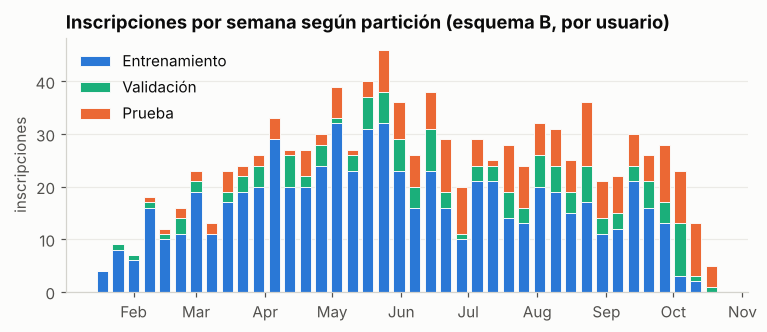

Guardado: 01_Datos/pares_usuario_curso.csv (una fila por par usuario-curso: positivo, peso, partición B y partición global A)


In [17]:
fig, ax = plt.subplots(figsize=(8, 3))
pp = par[par.positivo == 1].pivot_table(index=pd.Grouper(key="fecha_evento", freq="W"), columns="particion",
                                         values="positivo", aggfunc="sum").fillna(0).reindex(columns=["train", "valid", "test"])
bottom = np.zeros(len(pp))
for col, c, lab in [("train", AZUL, "Entrenamiento"), ("valid", AQUA, "Validación"), ("test", NARANJA, "Prueba")]:
    ax.bar(pp.index, pp[col], bottom=bottom, width=5, color=c, label=lab, edgecolor="#fcfcfb", linewidth=0.6)
    bottom += pp[col].values
ax.set_title("Inscripciones por semana según partición (esquema B, por usuario)"); ax.set_ylabel("inscripciones")
ax.legend(frameon=False, loc="upper left"); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b")); ax.grid(axis="x", visible=False)
guardar(fig, "11_particion_temporal"); plt.show()

par.to_csv(DATA / "pares_usuario_curso.csv", index=False)
print("Guardado: 01_Datos/pares_usuario_curso.csv (una fila por par usuario-curso: positivo, peso, partición B y partición global A)")

**Interpretación y decisión.** Con el corte global (A), solo 14 estudiantes tendrían a la vez historial en entrenamiento e inscripciones en prueba, porque muchos se registraron tarde. Con 14 usuarios, la diferencia entre modelos sería ruido. Con el corte por usuario (B) se evalúan **133 estudiantes**, siempre prediciendo sus inscripciones más recientes a partir de las anteriores, y quedan 17 estudiantes con menos de 3 inscripciones solo en entrenamiento.

El costo del esquema B es una **fuga entre usuarios**: el 30 % de los positivos de entrenamiento ocurre después de la fecha mediana de prueba. Es decir, al predecir a un estudiante, el modelo puede haber visto lo que otros hicieron después. Por eso el esquema A se reportará como prueba de robustez. Si el ranking de modelos se mantiene en ambos esquemas, la conclusión es confiable.

El archivo `pares_usuario_curso.csv` deja fijadas ambas particiones para que todos los modelos se evalúen exactamente sobre los mismos datos.

## 13. Conclusiones del EDA

1. **Calidad.** Los datos son consistentes y no requieren limpieza adicional. Los faltantes de `calificacion` son estructurales y los valores imputados del catálogo están marcados.
2. **Señal.** El problema es de feedback implícito. Se define como positivo un par con inscripción (991 positivos en 1 788 pares), y la intensidad (vista → finalización) se guarda como peso.
3. **Popularidad.** Está moderadamente concentrada (el 20 % de los cursos reúne el 46 % de las inscripciones; Gini 0.41): el baseline de popularidad será competitivo. Hay cola larga suficiente para que la personalización aporte valor.
4. **Idioma y perfil.** El idioma y el objetivo laboral explican buena parte de las elecciones. Las variables de usuario y de curso son informativas, lo que favorece al modelo de contenido y a LightFM. Se debe discutir que esto proviene de las reglas de simulación.
5. **Dispersión.** La matriz es 93.8 % dispersa, lo que es un reto para el KNN colaborativo y justifica ajustar *k* en validación.
6. **Evaluación.** Partición temporal por usuario (133 estudiantes evaluables), con el corte global como prueba de robustez. La popularidad y los modelos se entrenan solo con el conjunto de entrenamiento, y se usa K = 5 y K = 10.
7. **Cold start.** 17 estudiantes con menos de 3 inscripciones y cualquier estudiante nuevo se atenderán con una estrategia basada en el perfil (objetivo laboral, intereses, nivel, idioma), que se define en el notebook de modelamiento.